# Clasificacion de imagenes con ImageNette
## Notebook base en PyTorch con Transfer Learning

Este notebook introduce el flujo completo de un proyecto de vision por
computadora usando **transfer learning**. Usamos ImageNette, un
subconjunto de ImageNet con 10 clases faciles de distinguir, ideal para
prototipado rapido.

## Que es ImageNette

ImageNette fue creado por el equipo de fast.ai como un subconjunto de
ImageNet. Sus caracteristicas son:

- 13.394 imagenes a color.
- 9.469 para entrenamiento y 3.925 para validacion.
- 10 clases de objetos del mundo real.
- Imagenes de resolucion variable (desde 27x80 hasta 4368x2912).

Las 10 clases son:

| Indice | Clase |
|---|---|
| 0 | Tench (pez) |
| 1 | English springer (perro) |
| 2 | Cassette player |
| 3 | Chain saw |
| 4 | Church |
| 5 | French horn |
| 6 | Garbage truck |
| 7 | Gas pump |
| 8 | Golf ball |
| 9 | Parachute |

## Por que es util

- Es un benchmark rapido: entrena en minutos incluso en CPU.
- Las clases son visualmente muy distintas, lo que permite obtener
  buenos resultados con modelos simples.
- Es ideal para introducir **transfer learning** sin la complejidad de
  ImageNet completo.
- Permite comparar modelos entrenados desde cero vs. modelos
  preentrenados.

## Transfer Learning

En lugar de entrenar una CNN desde cero, reutilizamos un modelo
preentrenado en ImageNet (1.000 clases, 1.2 millones de imagenes). Las
capas convolucionales ya aprendieron a detectar bordes, texturas y
formas. Solo reemplazamos la capa final para adaptarla a nuestras 10
clases.

Estrategias:

- **Feature extraction**: congelar todo el backbone y entrenar solo la
  capa final.
- **Fine-tuning**: descongelar algunas capas del backbone y entrenar con
  learning rate bajo.

## Objetivos del notebook

Al finalizar, seras capaz de:

1. Cargar ImageNette con torchvision.
2. Aplicar transformaciones especificas para modelos preentrenados.
3. Cargar una ResNet18 preentrenada y adaptarla.
4. Entrenar con feature extraction y fine-tuning.
5. Evaluar con metricas robustas.
6. Visualizar filtros, feature maps y errores.

## Configuracion inicial

Importamos librerias, fijamos semillas y detectamos GPU.

In [4]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
)

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Dispositivo:", device)

PyTorch version: 2.7.1+cpu
Dispositivo: cpu


# 1. Carga del dataset

## Transformaciones

ImageNette tiene imagenes de resolucion variable. Para usar una ResNet18
preentrenada necesitamos redimensionar a 224x224, que es el tamano
estandar de ImageNet.

Definimos dos transformaciones:

- `transform_train`: con data augmentation. Aplicamos recorte aleatorio
  con padding y volteo horizontal.
- `transform_val`: sin augmentation. Solo resize y center crop.

La normalizacion usa los valores estandar de ImageNet:
media (0.485, 0.456, 0.406) y std (0.229, 0.224, 0.225).

## Descarga automatica

La primera vez que se ejecute esta celda, `torchvision` descargara el
dataset a la carpeta `./data`. Las siguientes ejecuciones reutilizaran
los archivos locales.

In [5]:
mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)

transform_train = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

transform_val = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_dataset = datasets.Imagenette(
    root="./data",
    split="train",
    size="full",
    download=True,
    transform=transform_train,
)

val_dataset = datasets.Imagenette(
    root="./data",
    split="val",
    size="full",
    download=True,
    transform=transform_val,
)

print("Train size:", len(train_dataset))
print("Val size:", len(val_dataset))

Train size: 9469
Val size: 3925


## Diagnostico de la estructura de classes

Antes de extraer los nombres, inspeccionamos que devuelve exactamente el
atributo `classes` en esta version de torchvision. Este diagnostico nos
permite manejar cualquier variante sin errores.

In [6]:
print("Tipo de train_dataset.classes:", type(train_dataset.classes))
print("Longitud:", len(train_dataset.classes))
print("Primeros 3 elementos:", train_dataset.classes[:3])
print("Tipo del primer elemento:", type(train_dataset.classes[0]))
print("Contenido del primer elemento:", train_dataset.classes[0])

Tipo de train_dataset.classes: <class 'list'>
Longitud: 10
Primeros 3 elementos: [('tench', 'Tinca tinca'), ('English springer', 'English springer spaniel'), ('cassette player',)]
Tipo del primer elemento: <class 'tuple'>
Contenido del primer elemento: ('tench', 'Tinca tinca')


## Extraccion robusta de nombres de clases

ImageNette usa los identificadores de WordNet (wnids) de ImageNet. Cada
wnid corresponde a un nombre legible. Definimos un diccionario con la
traduccion y una funcion que extrae los nombres sin importar la
estructura que devuelva torchvision.

Esto resuelve el error `IndexError: tuple index out of range` que ocurre
cuando la version de torchvision devuelve tuplas con distinta longitud o
estructuras inesperadas.

In [7]:
WNIDS_IMAGENETTE = {
    "n01440764": "tench",
    "n02102040": "English springer",
    "n02979186": "cassette player",
    "n03000684": "chain saw",
    "n03028079": "church",
    "n03394916": "French horn",
    "n03417042": "garbage truck",
    "n03425413": "gas pump",
    "n03445777": "golf ball",
    "n03888257": "parachute",
}


def obtener_nombres_clases(dataset, mapping=None):
    """
    Extrae los nombres legibles de las clases de un dataset de torchvision.

    Maneja distintos formatos:
    - lista de strings simples.
    - lista de tuplas (id, nombre).
    - lista de listas.
    - estructuras mixtas.

    Si el string corresponde a un wnid conocido en el mapping, se traduce.
    En caso contrario, se usa el string tal cual.
    """
    if mapping is None:
        mapping = {}

    def traducir(texto):
        if texto in mapping:
            return mapping[texto]
        return texto

    def extraer_string(objeto):
        # Caso 1: es un string directo
        if isinstance(objeto, str):
            return traducir(objeto) if objeto else None

        # Caso 2: es tupla o lista. Buscamos el ultimo string no vacio
        if isinstance(objeto, (tuple, list)):
            for item in reversed(objeto):
                if isinstance(item, str) and item:
                    return traducir(item)
            return None

        # Caso 3: cualquier otro tipo. Convertimos a string
        return str(objeto)

    nombres = []
    for c in dataset.classes:
        nombre = extraer_string(c)
        if nombre is None:
            nombre = str(c)
        nombres.append(nombre)

    return nombres


clases = obtener_nombres_clases(train_dataset, WNIDS_IMAGENETTE)
num_clases = len(clases)

print("Numero de clases:", num_clases)
for i, c in enumerate(clases):
    print(f"{i}: {c}")

Numero de clases: 10
0: Tinca tinca
1: English springer spaniel
2: cassette player
3: chainsaw
4: church building
5: horn
6: dustcart
7: island dispenser
8: golf ball
9: chute


# 2. Exploracion del dataset

## Inspeccion de una muestra

Cada imagen tiene shape (3, 224, 224) despues de las transformaciones.

In [8]:
imagen, etiqueta = train_dataset[0]
print("Shape de la imagen:", imagen.shape)
print("Etiqueta:", etiqueta)
print("Clase:", clases[etiqueta])
print("Valor minimo:", imagen.min().item())
print("Valor maximo:", imagen.max().item())

Shape de la imagen: torch.Size([3, 224, 224])
Etiqueta: 0
Clase: Tinca tinca
Valor minimo: -1.6726603507995605
Valor maximo: 2.483137607574463


## Visualizacion de ejemplos

Mostramos una imagen por clase. Desnormalizamos para verlas
correctamente.

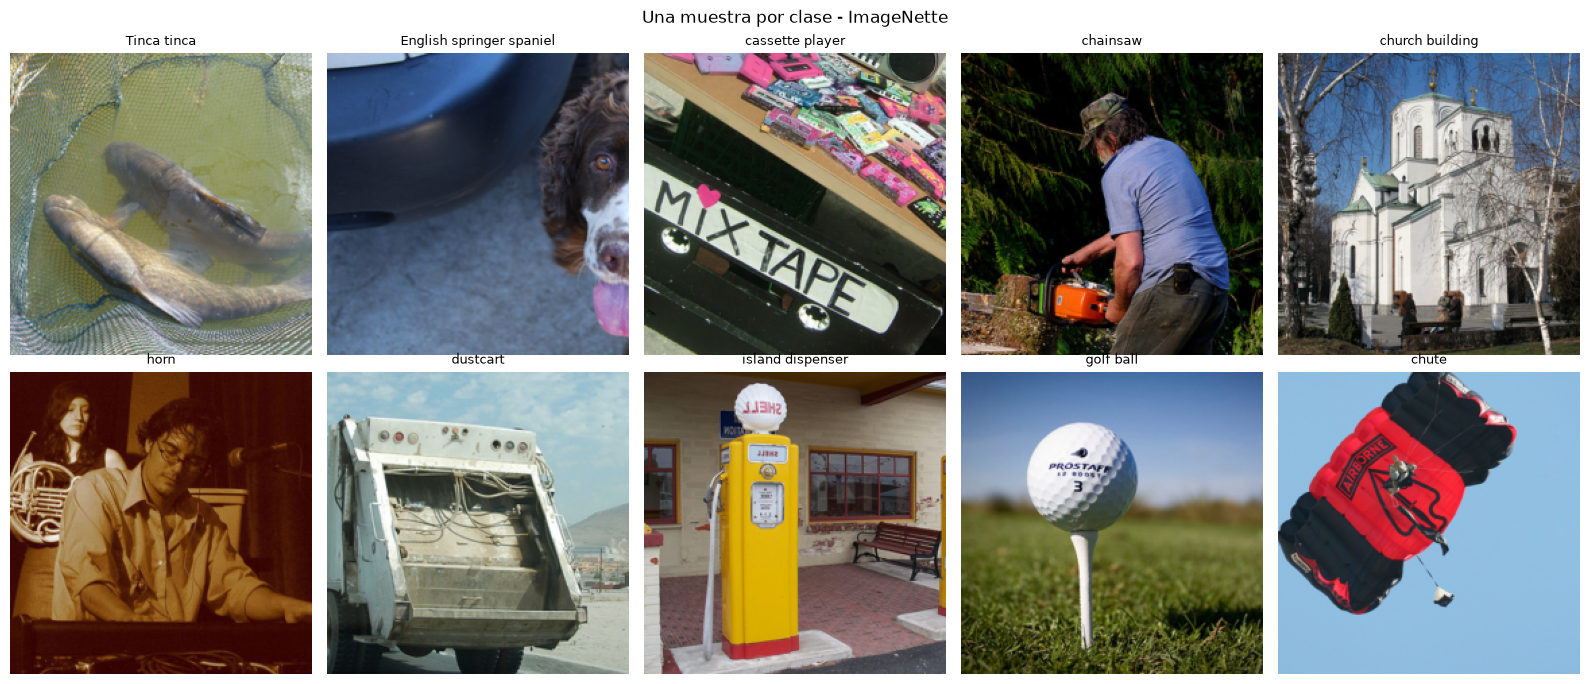

In [9]:
def desnormalizar(imagen, mean, std):
    img = imagen.clone()
    for c in range(3):
        img[c] = img[c] * std[c] + mean[c]
    return img.clamp(0, 1)


fig, axes = plt.subplots(2, 5, figsize=(16, 7))
contador = {i: 0 for i in range(num_clases)}

for imagen, etiqueta in train_dataset:
    if contador[etiqueta] == 0:
        ax = axes[etiqueta // 5, etiqueta % 5]
        img_vis = desnormalizar(imagen, mean, std).permute(1, 2, 0)
        ax.imshow(img_vis)
        ax.set_title(clases[etiqueta], fontsize=9)
        ax.axis("off")
        contador[etiqueta] += 1
    if all(v > 0 for v in contador.values()):
        break

plt.suptitle("Una muestra por clase - ImageNette")
plt.tight_layout()
plt.show()

## Distribucion de clases

Usamos `range(len(clases))` como posiciones en el eje x y
`tick_label=clases` para mostrar los nombres. Esto evita el error de
matplotlib al intentar convertir estructuras complejas en categorias.

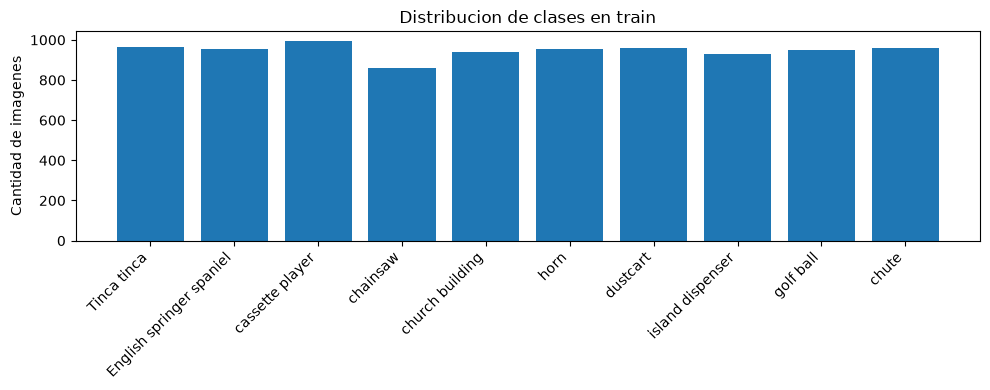

         Tinca tinca: 963 imagenes
English springer spaniel: 955 imagenes
     cassette player: 993 imagenes
            chainsaw: 858 imagenes
     church building: 941 imagenes
                horn: 956 imagenes
            dustcart: 961 imagenes
    island dispenser: 931 imagenes
           golf ball: 951 imagenes
               chute: 960 imagenes


In [10]:
etiquetas_train = [etiqueta for _, etiqueta in train_dataset]
conteo = np.bincount(etiquetas_train)

plt.figure(figsize=(10, 4))
plt.bar(range(len(clases)), conteo, tick_label=clases)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Cantidad de imagenes")
plt.title("Distribucion de clases en train")
plt.tight_layout()
plt.show()

for i, c in enumerate(clases):
    print(f"{c:>20}: {conteo[i]} imagenes")

# 3. DataLoaders

## Configuracion

Usamos batch size de 32 y `num_workers=2` para carga paralela.

In [11]:
batch_size = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

X_batch, y_batch = next(iter(train_loader))
print("Shape del batch de imagenes:", X_batch.shape)
print("Shape del batch de etiquetas:", y_batch.shape)

Shape del batch de imagenes: torch.Size([32, 3, 224, 224])
Shape del batch de etiquetas: torch.Size([32])


# 4. Modelo preentrenado

## Cargando ResNet18

Cargamos una ResNet18 preentrenada en ImageNet. La capa final original
tiene 1.000 salidas. La reemplazamos por una capa con 10 salidas, una
por cada clase de ImageNette.

## Congelando el backbone

Para feature extraction, congelamos todos los parametros del backbone y
dejamos entrenables solo los de la capa final.

In [12]:
modelo = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Congelamos todo el backbone
for param in modelo.parameters():
    param.requires_grad = False

# Reemplazamos la capa final
num_features = modelo.fc.in_features
modelo.fc = nn.Linear(num_features, num_clases)

modelo = modelo.to(device)

# Contamos parametros
def contar_parametros(modelo):
    total = sum(p.numel() for p in modelo.parameters())
    entrenables = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
    print(f"Parametros totales: {total:,}")
    print(f"Parametros entrenables: {entrenables:,}")

contar_parametros(modelo)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Usuario/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|█████████████████████████████████████████████████████████████████████████████| 44.7M/44.7M [00:07<00:00, 6.21MB/s]


Parametros totales: 11,181,642
Parametros entrenables: 5,130


## Resumen de la arquitectura

La ResNet18 tiene 18 capas con conexiones residuales. El backbone
extrae caracteristicas y la capa final clasifica.

In [13]:
print(modelo)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

# 5. Entrenamiento

## Fase 1: Feature Extraction

Entrenamos solo la capa final durante 5 epochs con learning rate 0.001.
El backbone permanece congelado.

In [14]:
def entrenar_epochs(modelo, train_loader, val_loader, epochs, lr, optimizer=None):
    if optimizer is None:
        parametros = filter(lambda p: p.requires_grad, modelo.parameters())
        optimizer = torch.optim.Adam(parametros, lr=lr)
    loss_fn = nn.CrossEntropyLoss()

    historial_train = []
    historial_val = []

    for epoch in range(epochs):
        modelo.train()
        perdida_total = 0.0
        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)
            optimizer.zero_grad()
            logits = modelo(X_batch)
            loss = loss_fn(logits, y_batch)
            loss.backward()
            optimizer.step()
            perdida_total += loss.item() * X_batch.size(0)
        train_loss = perdida_total / len(train_loader.dataset)
        historial_train.append(train_loss)

        modelo.eval()
        perdida_val = 0.0
        correctos = 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)
                logits = modelo(X_batch)
                loss = loss_fn(logits, y_batch)
                perdida_val += loss.item() * X_batch.size(0)
                correctos += (logits.argmax(1) == y_batch).sum().item()
        val_loss = perdida_val / len(val_loader.dataset)
        val_acc = correctos / len(val_loader.dataset)
        historial_val.append(val_loss)

        print(f"Epoch {epoch+1:>2}/{epochs} | "
              f"train: {train_loss:.4f} | val: {val_loss:.4f} | val acc: {val_acc:.4f}")

    return historial_train, historial_val


print("Fase 1: Feature Extraction")
hist_train_fe, hist_val_fe = entrenar_epochs(
    modelo, train_loader, val_loader, epochs=5, lr=0.001
)

Fase 1: Feature Extraction
Epoch  1/5 | train: 0.3466 | val: 0.0895 | val acc: 0.9794
Epoch  2/5 | train: 0.1139 | val: 0.0621 | val acc: 0.9834
Epoch  3/5 | train: 0.0894 | val: 0.0514 | val acc: 0.9834
Epoch  4/5 | train: 0.0762 | val: 0.0476 | val acc: 0.9857
Epoch  5/5 | train: 0.0732 | val: 0.0500 | val acc: 0.9847


## Curvas de aprendizaje - Fase 1

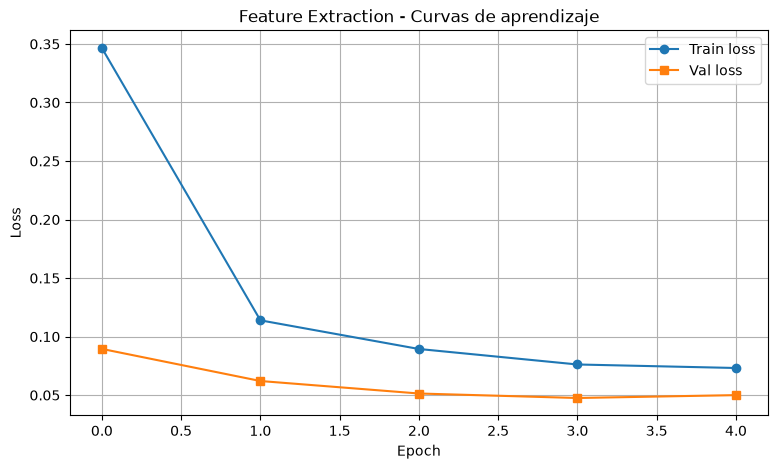

In [15]:
plt.figure(figsize=(9, 5))
plt.plot(hist_train_fe, marker="o", label="Train loss")
plt.plot(hist_val_fe, marker="s", label="Val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Feature Extraction - Curvas de aprendizaje")
plt.legend()
plt.grid(True)
plt.show()

## Fase 2: Fine-tuning

Descongelamos las ultimas capas del backbone (`layer4`) y entrenamos con
learning rates diferenciados: uno bajo para el backbone y uno mas alto
para la capa final.

In [16]:
# Descongelamos layer4
for param in modelo.layer4.parameters():
    param.requires_grad = True

# Optimizer con learning rates diferenciados
optimizer = torch.optim.Adam([
    {"params": modelo.layer4.parameters(), "lr": 1e-4},
    {"params": modelo.fc.parameters(), "lr": 1e-3},
])

print("Parametros entrenables despues de descongelar layer4:")
contar_parametros(modelo)

print()
print("Fase 2: Fine-tuning")
hist_train_ft, hist_val_ft = entrenar_epochs(
    modelo, train_loader, val_loader, epochs=5, lr=1e-4, optimizer=optimizer
)

Parametros entrenables despues de descongelar layer4:
Parametros totales: 11,181,642
Parametros entrenables: 8,398,858

Fase 2: Fine-tuning
Epoch  1/5 | train: 0.1102 | val: 0.0681 | val acc: 0.9789
Epoch  2/5 | train: 0.0615 | val: 0.0686 | val acc: 0.9783
Epoch  3/5 | train: 0.0540 | val: 0.0712 | val acc: 0.9761
Epoch  4/5 | train: 0.0449 | val: 0.0706 | val acc: 0.9786
Epoch  5/5 | train: 0.0363 | val: 0.0888 | val acc: 0.9730


## Curvas de aprendizaje - Fase 2

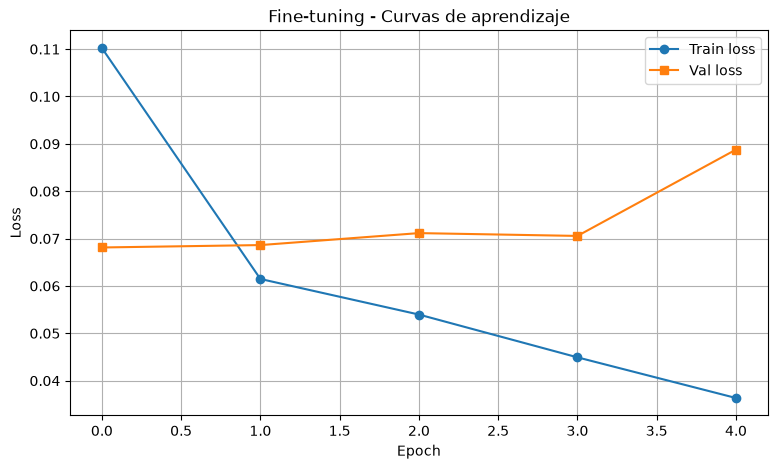

In [17]:
plt.figure(figsize=(9, 5))
plt.plot(hist_train_ft, marker="o", label="Train loss")
plt.plot(hist_val_ft, marker="s", label="Val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Fine-tuning - Curvas de aprendizaje")
plt.legend()
plt.grid(True)
plt.show()

## Curvas combinadas

Comparamos ambas fases en una misma grafica.

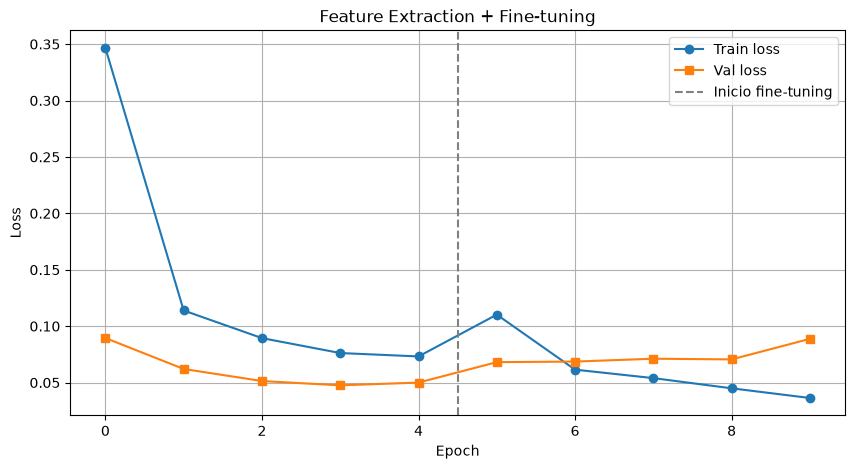

In [18]:
hist_train_total = hist_train_fe + hist_train_ft
hist_val_total = hist_val_fe + hist_val_ft

plt.figure(figsize=(10, 5))
plt.plot(hist_train_total, marker="o", label="Train loss")
plt.plot(hist_val_total, marker="s", label="Val loss")
plt.axvline(len(hist_train_fe) - 0.5, color="gray", linestyle="--",
            label="Inicio fine-tuning")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Feature Extraction + Fine-tuning")
plt.legend()
plt.grid(True)
plt.show()

# 6. Evaluacion en test

## Predicciones y metricas

In [19]:
def obtener_predicciones(modelo, loader):
    modelo.eval()
    todas_pred = []
    todas_etiquetas = []
    todas_probs = []
    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            logits = modelo(X_batch)
            probs = F.softmax(logits, dim=1)
            pred = logits.argmax(dim=1)
            todas_pred.append(pred.cpu().numpy())
            todas_etiquetas.append(y_batch.numpy())
            todas_probs.append(probs.cpu().numpy())
    return (
        np.concatenate(todas_pred),
        np.concatenate(todas_etiquetas),
        np.concatenate(todas_probs),
    )


y_pred, y_true, y_probs = obtener_predicciones(modelo, val_loader)

accuracy = (y_pred == y_true).mean()
print(f"Accuracy en validacion: {accuracy:.4f}")
print()
print("Reporte por clase:")
print(classification_report(y_true, y_pred, target_names=clases, digits=4))

Accuracy en validacion: 0.9730

Reporte por clase:
                          precision    recall  f1-score   support

             Tinca tinca     0.9948    0.9793    0.9870       387
English springer spaniel     0.9924    0.9924    0.9924       395
         cassette player     0.9883    0.9440    0.9656       357
                chainsaw     0.9386    0.9508    0.9447       386
         church building     0.9734    0.9853    0.9793       409
                    horn     0.9921    0.9619    0.9768       394
                dustcart     0.9819    0.9769    0.9794       389
        island dispenser     0.9229    0.9714    0.9465       419
               golf ball     0.9873    0.9774    0.9824       399
                   chute     0.9673    0.9872    0.9772       390

                accuracy                         0.9730      3925
               macro avg     0.9739    0.9727    0.9731      3925
            weighted avg     0.9735    0.9730    0.9731      3925



## Matriz de confusion

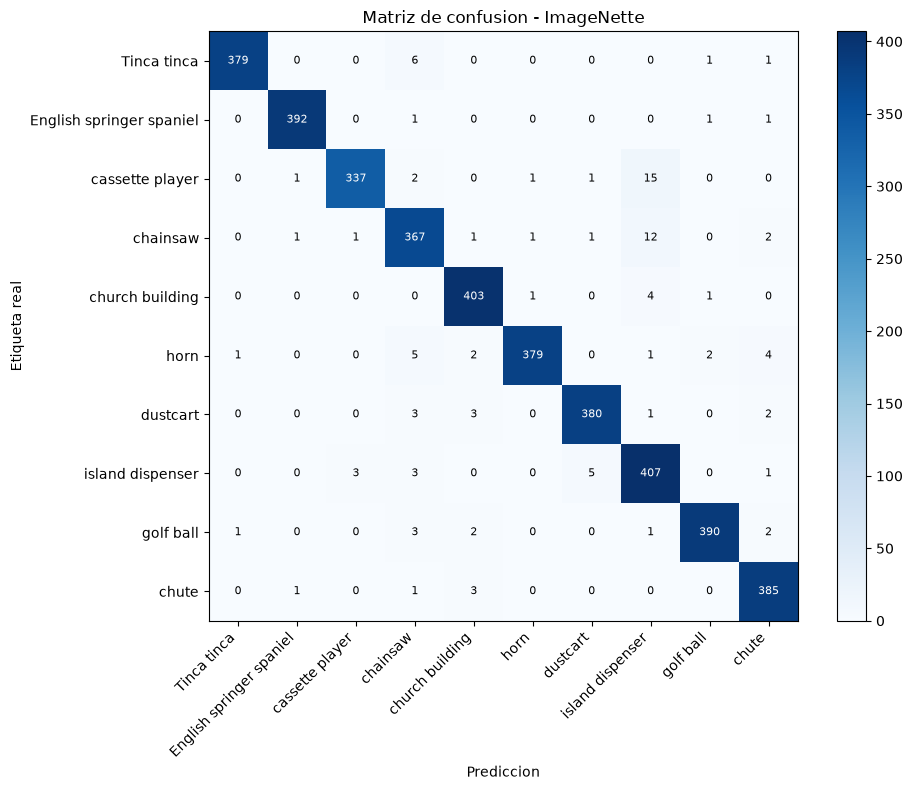

In [20]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(num_clases), clases, rotation=45, ha="right")
plt.yticks(range(num_clases), clases)
plt.xlabel("Prediccion")
plt.ylabel("Etiqueta real")
plt.title("Matriz de confusion - ImageNette")
for i in range(num_clases):
    for j in range(num_clases):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black",
                 fontsize=8)
plt.tight_layout()
plt.show()

## Observaciones tipicas

En ImageNette los errores son poco frecuentes gracias a que las clases
son visualmente muy distintas. Algunas confusiones posibles:

- English springer vs. Tench: ambos pueden aparecer en fondos naturales.
- Cassette player vs. Gas pump: objetos con formas rectangulares.
- French horn vs. Parachute: formas curvas.

Un accuracy superior al 95 por ciento es esperable con transfer
learning.

# 7. Visualizacion de filtros

## Filtros de la primera capa convolucional de ResNet18

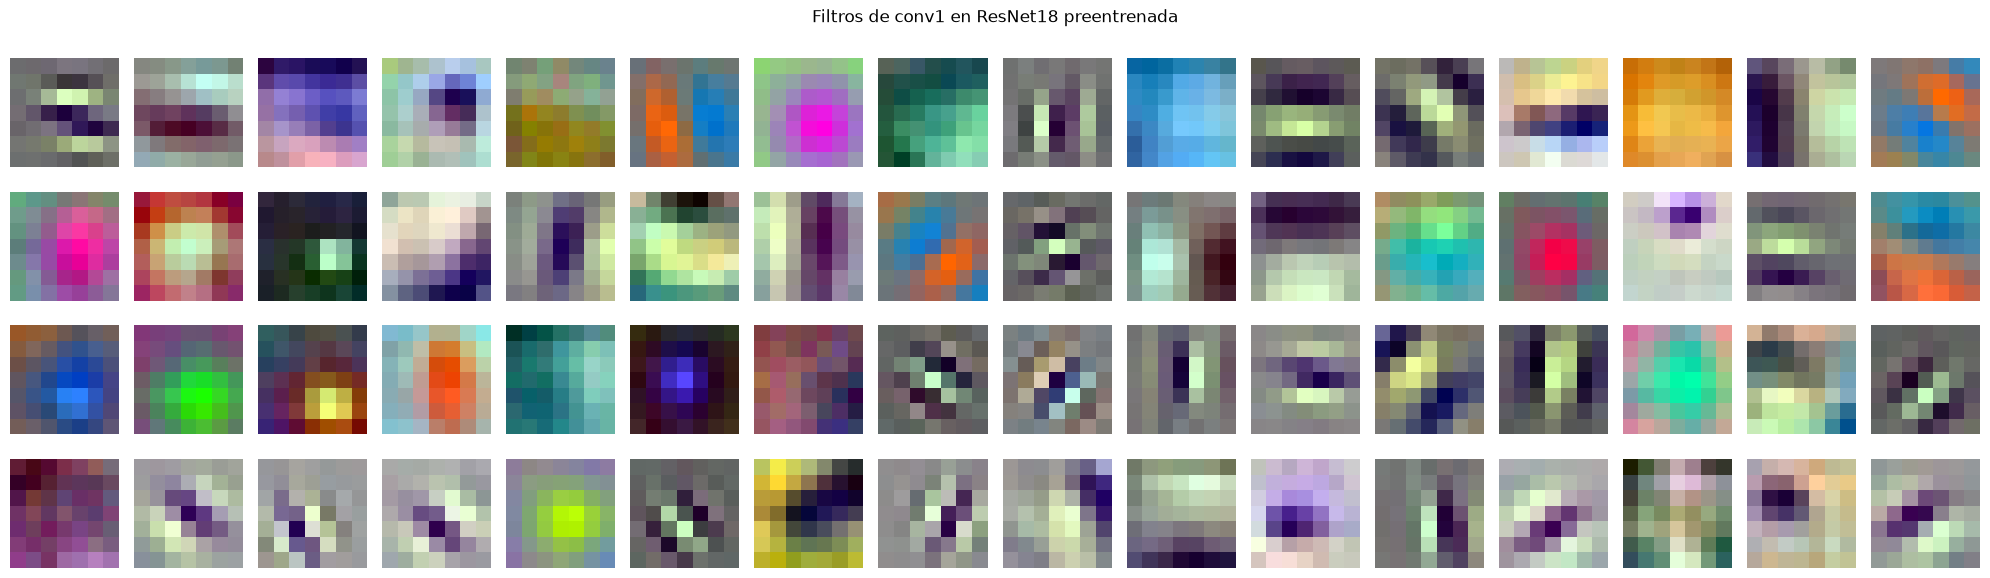

In [21]:
filtros = modelo.conv1.weight.detach().cpu()

fig, axes = plt.subplots(4, 16, figsize=(20, 6))
for i, ax in enumerate(axes.flat):
    if i < filtros.shape[0]:
        filtro = filtros[i].permute(1, 2, 0)
        filtro = (filtro - filtro.min()) / (filtro.max() - filtro.min() + 1e-8)
        ax.imshow(filtro)
    ax.axis("off")
plt.suptitle("Filtros de conv1 en ResNet18 preentrenada")
plt.tight_layout()
plt.show()

## Interpretacion

Los filtros de la primera capa detectan bordes, gradientes de color y
texturas simples. Al estar preentrenados en ImageNet, estos filtros ya
son genericos y utiles para cualquier tarea de vision.

# 8. Visualizacion de feature maps

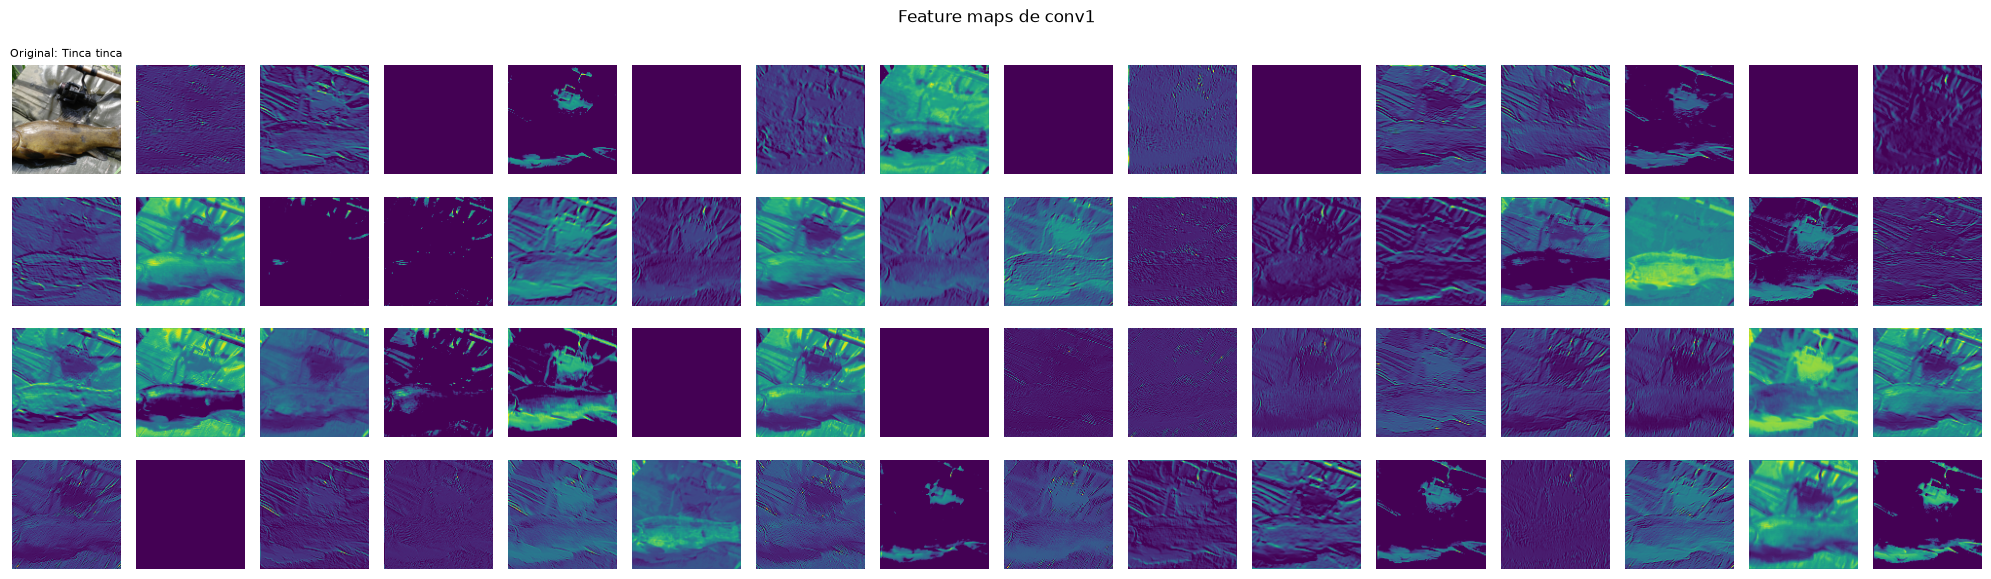

In [22]:
imagen, etiqueta = val_dataset[0]
imagen_tensor = imagen.unsqueeze(0).to(device)

# Extraemos activaciones de la primera capa
with torch.no_grad():
    activaciones = F.relu(modelo.bn1(modelo.conv1(imagen_tensor))).cpu().squeeze(0)

fig, axes = plt.subplots(4, 16, figsize=(20, 6))
axes[0, 0].imshow(desnormalizar(imagen, mean, std).permute(1, 2, 0))
axes[0, 0].set_title(f"Original: {clases[etiqueta]}", fontsize=8)
axes[0, 0].axis("off")

for i, ax in enumerate(axes.flat[1:]):
    if i < activaciones.shape[0]:
        ax.imshow(activaciones[i], cmap="viridis")
    ax.axis("off")
plt.suptitle("Feature maps de conv1")
plt.tight_layout()
plt.show()

# 9. Analisis de errores

Total de errores: 106 de 3925



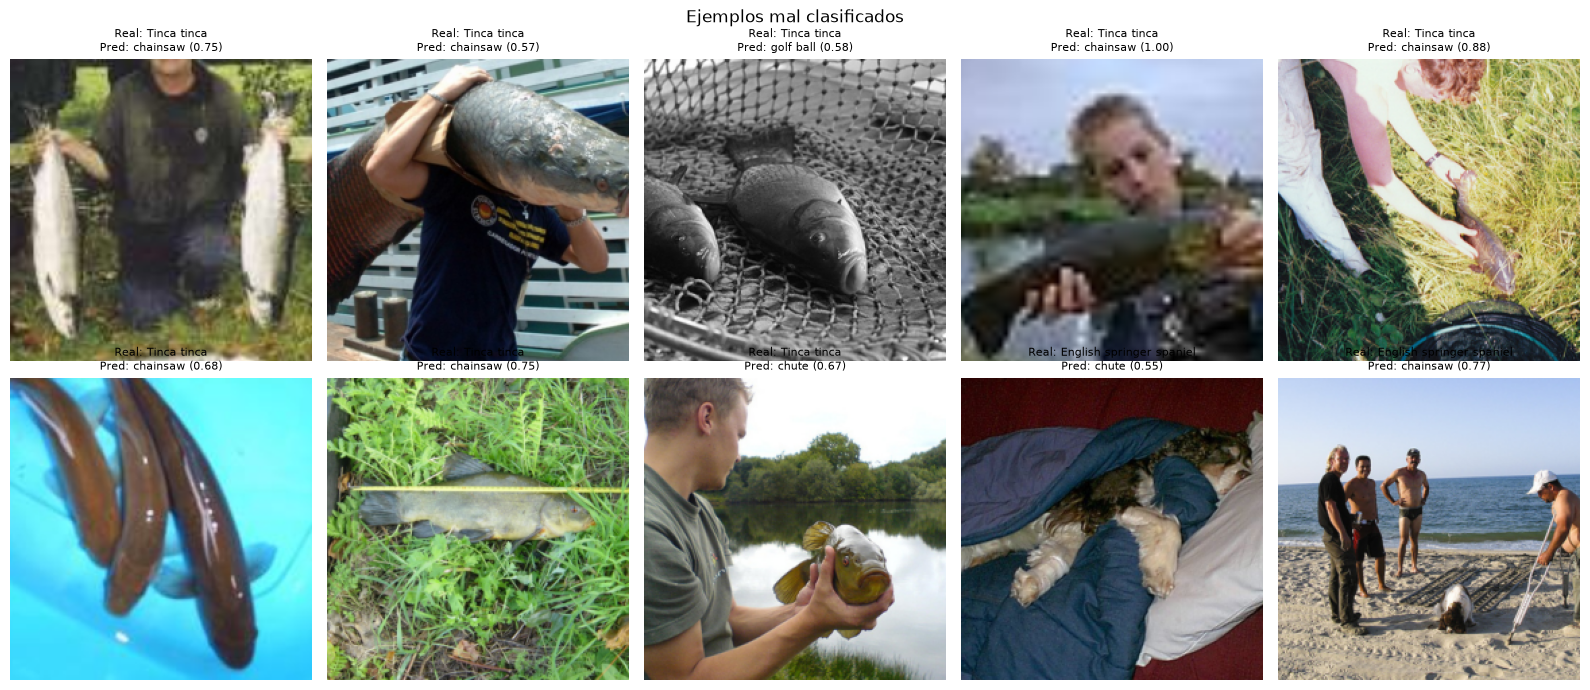

In [23]:
indices_error = np.where(y_pred != y_true)[0]
print(f"Total de errores: {len(indices_error)} de {len(y_true)}")
print()

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for i, ax in enumerate(axes.flat):
    if i < min(10, len(indices_error)):
        idx = indices_error[i]
        img, _ = val_dataset[idx]
        img_vis = desnormalizar(img, mean, std).permute(1, 2, 0)
        ax.imshow(img_vis)
        prob_pred = y_probs[idx, y_pred[idx]]
        ax.set_title(
            f"Real: {clases[y_true[idx]]}\n"
            f"Pred: {clases[y_pred[idx]]} ({prob_pred:.2f})",
            fontsize=8,
        )
    ax.axis("off")
plt.suptitle("Ejemplos mal clasificados")
plt.tight_layout()
plt.show()

## Preguntas para reflexionar

1. La mayoria de errores ocurren en imagenes ambiguas o con objetos poco
   visibles.
2. El modelo suele asignar alta confianza a sus predicciones, incluso
   cuando se equivoca.
3. Transfer learning permite obtener buenos resultados con pocos datos
   y poco tiempo de entrenamiento.

# 10. Comparacion: desde cero vs. transfer learning

Para contextualizar la ventaja del transfer learning, comparamos con una
CNN simple entrenada desde cero.

In [ ]:
class CNNBasica(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(64 * 56 * 56, 128)
        self.fc2 = nn.Linear(128, num_clases)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x


modelo_basico = CNNBasica().to(device)
contar_parametros(modelo_basico)

print()
print("Entrenando CNN desde cero...")
hist_train_basico, hist_val_basico = entrenar_epochs(
    modelo_basico, train_loader, val_loader, epochs=5, lr=0.001
)

y_pred_basico, y_true_basico, _ = obtener_predicciones(modelo_basico, val_loader)
acc_basico = (y_pred_basico == y_true_basico).mean()
print(f"Accuracy CNN desde cero: {acc_basico:.4f}")

Parametros totales: 25,710,922
Parametros entrenables: 25,710,922

Entrenando CNN desde cero...
Epoch  1/5 | train: 2.1389 | val: 1.6807 | val acc: 0.4438


## Comparacion final

In [ ]:
y_pred_tl, y_true_tl, _ = obtener_predicciones(modelo, val_loader)
acc_tl = (y_pred_tl == y_true_tl).mean()

print("Resumen de resultados:")
print(f"CNN desde cero:     {acc_basico:.4f}")
print(f"Transfer learning:  {acc_tl:.4f}")
print(f"Mejora:             {(acc_tl - acc_basico) * 100:.2f} puntos porcentuales")

# 11. Resumen

## Lo que hicimos

- Cargamos ImageNette con torchvision.
- Aplicamos transformaciones para ResNet18 (224x224).
- Cargamos una ResNet18 preentrenada en ImageNet.
- Congelamos el backbone y entrenamos solo la capa final.
- Descongelamos layer4 y hicimos fine-tuning.
- Evaluamos con accuracy, precision, recall, F1 y matriz de confusion.
- Visualizamos filtros, feature maps y errores.
- Comparamos con una CNN entrenada desde cero.

## Resultados esperados

- Accuracy con transfer learning: 95 a 98 por ciento.
- Accuracy con CNN desde cero: 70 a 85 por ciento.
- La mejora es significativa y se obtiene en menos epochs.

## Ventajas del transfer learning

- Requiere menos datos.
- Entrena mas rapido.
- Obtiene mejores resultados.
- Aprovecha conocimiento previo de ImageNet.

## Cuando usar transfer learning

- Cuando el dataset es pequeno o mediano.
- Cuando la tarea es similar a la del modelo preentrenado.
- Cuando no hay tiempo o recursos para entrenar desde cero.

## Referencias

- ImageNette: https://github.com/fastai/imagenette
- ResNet paper: https://arxiv.org/abs/1512.03385
- Documentacion de torchvision: https://pytorch.org/vision/stable/
- Documentacion de PyTorch: https://pytorch.org/docs/stable/